# Digital Twin Integration
by Chris Mimra (UniSQ) 2026

This notebook serves as Software Requirement Document and code-illustration of the scientifically relevant software parts. It is produced by a human who takes full responsibility. The production system is developed in parallel by an AI agent based on the criteria in this notebook. The scientifically non-relevant parts are called from the AI-generated libraries from the production environment. The software is transferred to a Windows workstation. The polarisation camera and a touch monitor are connected to it.

## How we work

The process follows Matt Pocock's coding workflow. This notebook replaces GitHub issues.
1. **Grill-me on the whole plan** to reach a shared understanding of the system and of the interfaces between slices.
2. **Per slice (sections 0–7):** a grill-me on the implementation, then a **Specs** subsection, then a **Tickets** subsection with bullet points, then implementation. Each ticket is deleted once it is implemented, and the Tickets subsection is deleted when it is empty. The Specs subsection stays as the record of the slice.
3. **Validation** uses tests (pytest) and a CI check that runs locally (`uv run python tools/ci.py`), because GitHub automations are not available. Tests run on **synthetic data** with a known answer, because no existing dataset contains matching calibration and tow data. The generator lives in `src/synthetic_data/` (git-ignored, not part of the notebook). It creates **one** synthetic dataset, which is committed; all tests use that dataset, so a fresh clone does not need the generator.
4. **Scientific code is written in the notebook.** Production copies these functions, and a reference test checks that the production code gives the same results as the notebook on the same synthetic data.
5. **Keep it slim.** Decisions that are critical for understanding the system, or for its scientific value, go into the main sections. Other implementation decisions go into section 8 and are deleted from there once they are implemented.

## General software structure

The monitoring system consists of 7 slices. Each slice reads and writes files only, so every slice can be run on its own in the notebook or in production. Each run has one **run folder** holding `run.json` (run ID, references to the calibration bundle and tow file, camera settings, tow width, frame log) and the files of all slices, named by revolution index. The calibration bundle has its own folder, and a run refers to it. The first version processes a finished run offline. Each tow is evaluated on its own; layers play no role.

| # | Slice | Runs | Notebook | Consumes | Produces |
| - | ----- | ---- | -------- | -------- | -------- |
| 1 | Preview | Live | No | Camera stream | Camera settings (gain, exposure, save location) |
| 2 | Calibration | Per installation | No | Checkerboard images, empty-mandrel images, mandrel STEP | Calibration bundle |
| 3 | Data capturing | Per run | No | Camera settings, trigger pulses | Reference frame of the empty mandrel, raw frames (one per revolution), frame log (timestamp per frame) |
| 4 | Conversion | Per frame | Yes | Raw frame, polariser pattern | S0, S1, S2, DoLP, AoLP |
| 5 | Mapping | Per frame | Yes | AoLP, DoLP, calibration bundle | Per pixel: 3D point, surface normal, fibre angle (NaN off the mandrel); gnomonic image |
| 6 | Tow matching | Per frame | Yes | Mapped frames *k−1* and *k*, planned path | Table per revolution and visible crossing (planned position and angle, Δ position, Δ angle; "not visible" if none), overlay image |
| 7 | Data export | Per run | Yes | Outputs of 2–6 | Tow table (CSV) and mapped arrays; the 3DEXPERIENCE adapter comes later |

### Shared conventions
- One coordinate frame, the origin of the mandrel STEP file. Units are mm and degrees.
- Image angles (AoLP, `polar_pattern`) are measured from the image +x axis (columns, to the right) towards +y (rows, downwards), in (−90°, 90°].
- The mandrel enters the system as a triangle mesh in the STEP frame, converted once during calibration. Its rotation axis (a point and a direction) is entered with the STEP file and checked during calibration.
- The fibre angle lies in (−90°, 90°]. It is measured in the local surface plane from the mandrel axis direction, positive towards the surface direction of mandrel rotation. Planned and measured angles use the same definition.
- The planned path and the mesh share the STEP frame. Path points further than one tow width from the mesh (lead-in and lead-out) are ignored.
- The trigger pin fires exactly one frame per revolution at a fixed mandrel angle, and the camera does not move during a run. All frames of a run therefore share the same pixel-to-surface geometry, which is computed once per part. Motion blur and trigger jitter are treated as uncertainty, not corrected.
- A frame is identified by run ID and revolution index. Revolution indices come from the frame timestamps divided by the nominal period, not from counting frames, so pin bounces and missed pulses do not shift the count.
- **Touch-down model:** the tow lands on the mandrel at a constant machine angle φ_touch. Each planned-path point gets its unwrapped body angle φ around the mandrel axis (counter-clockwise about the oriented axis, zero at the STEP X direction). A point touches down when mandrel angle + φ = φ_touch, so later tow lies at smaller φ. The mandrel angle when laid is θ = θ₀ + (φ₀ − φ), with θ₀ = (φ_touch − φ₀ − pin phase) mod 360° for the first point, and the point lies in revolution k = floor(θ / 360°). This requires the mandrel to turn in one direction only. The free fibre length between the payout eye and the mandrel is ignored.
- **Measured tow:** because all frames share the same geometry, the tow laid in revolution *k* is the set of pixels whose AoLP or DoLP changed significantly between frames *k−1* and *k*. For *k = 0* the reference frame of the empty mandrel is used.

Implementation order: forward model (section 5) → synthetic dataset (section 0, cylinder) → 4 Conversion → 5 Mapping with forward model, then the banana dataset → 6, 7 → production-only 3, 1, 2. The calibration bundle is synthetic until slice 2 exists.

### Glossary
- **Run**: the winding of one part, from *record* to *stop*. One run folder.
- **Revolution**: one full turn of the mandrel, counted from the trigger pin. Indexed *k*.
- **Frame**: one raw image, captured once per revolution by the pin. Frame *k* belongs to revolution *k*. The **reference frame** shows the empty mandrel before winding.
- **Tow**: the band laid during one revolution. It is the unit of evaluation.
- **Pin phase**: the mandrel angle at which a frame is exposed, in the STEP frame, including the trigger delay.
- **Touch-down angle (φ_touch)**: the constant machine angle at which the tow first touches the mandrel.
- **Calibration bundle**: intrinsics, distortion, image size, camera pose, mandrel axis, pin phase, touch-down angle and mandrel mesh of one installation. It stays valid until the camera is moved.
- **Planned path**: the tow centre line from the tow placement file (CSV of points X, Y, Z in mm). **Planned tow**: the band of tow width around it. **As-laid path**: the path the tow actually took (known only in synthetic data).
- **Fibre angle**: the angle between the fibre direction and the mandrel axis, in the local surface plane, in (−90°, 90°].

## 0 Synthetic dataset

Production-only tooling, not part of the notebook's scientific code. A generator in `src/synthetic_data/` (git-ignored) creates **one** dataset, which is committed. All tests and the notebook examples use it. It contains `demoData/synthetic/cylinder/` (from `WindingDummieSym.step`, helical path) and `demoData/synthetic/banana/` (from `Banana 1.STEP` and `planned_Path.csv`). Each holds a calibration bundle and a run folder with a reference frame and 3 revolutions at full resolution, stored compressed.

- **Camera:** acA4112-30umPOL (3.45 µm pixels) with the AIAC22 16 mm lens, 700 mm from the mandrel axis, optical axis perpendicular to the mandrel axis through the middle of the part, radial distortion k1 = −0.05.
- **Cylinder:** axis = Z through the origin, winding surface r = 125 mm between z = −185 and 185 mm (rounded ends beyond). Path: one helical pass over z = −180…180 mm in 3 revolutions (fibre angle ≈ −81°). With touch-down 180° and pin phase 0°, each tow crosses the view once, at z = −120, 0 and 120 mm. Size: 83 MB.
- **Banana:** axis = Y through the origin, defined by the rod. The STEP file and `planned_Path.csv` already share this frame. The mesh holds both banana halves and the visible rod sections; dowels and inner tube are left out. The camera looks at y ≈ 300 mm. Path revolutions 0–2 are used.
- **Ground truth:** an **as-laid path** = planned path with, per revolution, a lateral offset d_k ∈ ±2 mm (in the surface, perpendicular to the path) and an angle error δ_k ∈ ±1° (rotation about the crossing point, where the path crosses the plane through the camera centre and the mandrel axis), fixed seed. Revolution 0 has zero error.
- **Rendering:** forward model (section 5), polariser pattern, shot noise, 12-bit quantisation, low-DoLP background, a fixed random AoLP per pixel on bare mandrel and background (so only a new tow changes between frames), earlier tows under the new one. Motion blur, specular highlights and vignetting are left out.

### Specs

**Problem.** No dataset exists with matching calibration, frames, planned path and known deviations, so no slice can be tested against a known answer.

**Solution.** A one-off generator writes a complete, committed dataset for both mandrels in exactly the file format that the production slices read and write. A fresh clone needs only the dataset.

**User stories**
1. As the researcher, I want a dataset with known fibre angles and tow deviations, so that every slice can be tested against a true answer.
2. As the researcher, I want the dataset in the same file format as a real run, so that the notebook and production read synthetic and real runs identically.
3. As the researcher, I want a symmetric and an asymmetric mandrel, so that Mapping is tested beyond analytic surfaces.
4. As the researcher, I want frames rendered with the notebook's forward model, so that the synthetic AoLP follows the model I take responsibility for.
5. As the researcher, I want revolution 0 laid without error, so that a method that reports deviations where there are none is caught.
6. As the researcher, I want a reference frame of the empty mandrel, so that the measured tow of revolution 0 can be found.
7. As the researcher, I want earlier tows to stay visible under the new one, so that the change between frames *k−1* and *k* is tested realistically.
8. As the researcher, I want realistic noise and 12-bit raw values, so that Conversion and the change detection see camera-like data.
9. As the developer, I want the dataset generated once and committed, so that tests are deterministic and need no generator.
10. As the developer, I want one loader for calibration bundles and run folders, so that every slice uses the same file interface.
11. As the developer, I want per-pixel ground-truth geometry and fibre angles, so that Mapping can be tested pixel by pixel.

**Implementation decisions**
- **Forward model module** (`digital_thread`): the section 5 functions, written in the notebook and copied into the package: local fibre frame, fibre angle → AoLP, AoLP → fibre angle, plus rendering of S0 and DoLP. The generator imports it from the package.
- **Dataset I/O module** (`digital_thread`): reads and writes the calibration bundle and the run folder. This is the one interface every slice uses.
- **Calibration bundle** = `calibration.json` + `mesh.npz` (vertices, faces and outward CAD normals per vertex, STEP frame, mm). The JSON holds: image size and intrinsics K of the **super-pixel image** (2048×1500, the resolution of S0/DoLP/AoLP), distortion coefficients in OpenCV order, camera pose as R and t with x_cam = R·X + t, mandrel axis (point, direction oriented by the right-hand rule with the mandrel rotation), pin phase, touch-down angle.
- **Run folder** = `run.json` + frames. The JSON holds: run ID, relative path to the calibration bundle, tow file name, tow width (6.35 mm), polariser pattern, camera settings, nominal period, and the frame log (file name and timestamp per frame, including the reference frame). Raw frames are compressed `.npz` (key `raw`, uint16, 3000×4096), named `reference_raw.npz` and `rev000_raw.npz`, `rev001_raw.npz`, … Production capture uses the same format. The planned path is copied into the run folder in the demo CSV format.
- **Ground truth** (synthetic runs only): `truth.json` (d_k, δ_k, crossing point per revolution, seed), `as_laid_path.csv`, `truth_geometry.npz` (3D point and normal per super-pixel, NaN off the mandrel), and `revNNN_truth.npz` (true fibre angle and revolution of the top tow per super-pixel; NaN / −1 where no tow is visible).
- **Revolution assignment** in the generator uses the touch-down model from *Shared conventions*, with pin phase and φ_touch written to the calibration bundle, so slice 6 assigns the same tows to the same revolutions.
- **Rendering:** one ray per super-pixel, cast once per mandrel, since the geometry is the same for all frames. The 4 polariser pixels of a super-pixel share that ray, and I_θ = S0/2 · (1 + DoLP · cos 2(ψ − θ)). Coverage: a surface point belongs to tow k if it lies within half a tow width of the as-laid centre line of revolution k; the newest tow is on top. The fibre direction is the local tangent of that centre line, projected into the tangent plane. Shot noise is Poisson at about 10 500 e⁻ full well; values are quantised and clipped to 0…4095.
- **Timestamps:** nominal period 12 s (≈ 0.083 rev/s); the reference frame is one period before revolution 0. The dataset contains no bounces or missed pulses.
- **Generator** (`src/synthetic_data/`, git-ignored): STEP → mesh (gmsh), camera rays with distortion (fixed-point inversion of the OpenCV distortion model), ray casting (Open3D), path perturbation, rendering, writing through the dataset I/O module. It is not tested itself; the committed dataset is.

**Testing decisions**
- Tests check external behaviour only, through two seams: the **dataset I/O module** (loading the committed dataset) and the **forward model module**.
- Dataset tests: both mandrels load completely; image sizes agree between bundle and frames; raw values are uint16 ≤ 4095; timestamps rise by about one period; revolution 0 has zero error and all d_k, δ_k are within bounds; every revolution's tow crosses the view (true fibre angle present in `revNNN_truth.npz`).
- Forward model tests: AoLP → fibre angle inverts fibre angle → AoLP over random geometry within the incidence limit; a hand-checked case (camera square to the cylinder, fibre along the axis) gives the expected AoLP.
- Reference test: the package forward model gives the same results as the notebook's section 5 code on fixed inputs.
- Prior art: none yet; pytest and ruff are configured in `pyproject.toml`.

**Out of scope:** motion blur, specular highlights, vignetting, pin bounces and missed pulses in the data, calibration images (checkerboard), more than 3 revolutions, physical validation.

**Further notes.** The dataset is regenerated whenever the forward model changes. New dependencies (gmsh, Open3D, SciPy; uv group `generator`) are for the generator; whether Open3D also serves Mapping in production is decided in the slice 5 grill.

### Tickets
- **T5 Banana dataset** (blocked by: T4; scheduled after slice 5 per the implementation order). Assembly without dowels and inner tube, axis Y, `planned_Path.csv` revolutions 0–2, camera at y ≈ 300 mm. All dataset tests run on both mandrels.

In [1]:
# Imports:

import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

from digital_thread import dataset  # production I/O (not scientific code)

# User variables (for purposes of this notebook, these are hard-coded):
repo = Path.cwd() if (Path.cwd() / "demoData").exists() else Path.cwd().parent
run_folder = repo / "demoData" / "synthetic" / "cylinder" / "run"  # synthetic run (section 0)
frame_name = "rev002"  # frame to convert: "reference", "rev000", "rev001", "rev002"
save_location = repo / "notebooks" / "temp_data" / f"synthetic_cylinder_{frame_name}"

# System settings (hard-coded for notebook, changable in prod UI):
DoLP_threshold = 0.1 # What DoLP value to use as a threshold for masking AoLP values 
polar_pattern = (90, 45, 135, 0) # Polariser angle of each pixel in a 2x2 super-pixel: (top-left, top-right, bottom-left, bottom-right).
view_incidence_threshold = 20

## 1 Preview 

The camera (Basler acA4112-30umPOL - 2048×1500 super-pixels) records images and saves them as .npy files.
The basler pypylon library is used. 

### Requirements
- Production only, as jupyter doesn't support real-time streams.
- Settings (save location, gain, shutter speed) are manually set
- Add a saturation warning.
- A focus setting option with a preview with highlighted sharp edges
- A GUI with buttons optimised for touch-screen usage. 

## 2 Calibration

This module's purpose is to calibrate the camera system. It consists of two sub systems:
A) Intrinsic calibration of the camera optics: A calibration procedure with a flat calibration board with a checkered pattern is conducted and the intrinsic calibration of the camera is determinded. 
B) Capture the exact position and viewing angle of the camera system, when it is triggered. It works by capturing images of the empty mandrel and comparing reference points to a digital model. From this comparison, the relative position of the camera, it's viewing angle and the rotational position of the trigger on the mandrel.

### Prerequesites
- Set up camera on tripod
- Mechanical triggering system that inititates an image capturing once every revolution of the mandrel. Its a mechanical system with a pin on the rotating axis and is connected to GPIO26 of the RaspPi.
- Flat calibration board with 10x7 tiles on A3 sheet.
- Reference points on empty mandrel and digital model (ARUCO marker + symmetry lines)

### Requirements
- Calibration button on the UI with two tabs: Intrinsic optic and position calibration
- Guided calibration (intrinsic optics) with 12 positions of the board. Automatic extraction of the intrinsic matrices and distortion removal.
- Import of the mandrel's step file. 
- Automated calibration of the camera position in realation to the mandrel through 5 rotations of the mandrel. It saves the positon of the camera in relation to the mandrel's step file origin position. It also saves the rotational position of the trigger pin on the mandrel and  field of view of the camera in relaition to the mandrel.


# 3 Data capturing 

This module captures the raw data from the camera, when the GUI button "record" is activated. It saves the raw data as npy files. There is a GUI slider if the processing of the data should automatically be started or if it is done offline.

Before winding starts, a reference frame of the empty mandrel is captured at the pin phase. Each frame is written with its timestamp into the frame log of the run. The revolution index is derived from the timestamps (see *Shared conventions*): frames closer together than half a period are dropped as pin bounces, and gaps are flagged in the run log.

## 4 Conversion

### Prerequesites
The previously captured files are loaded and previewed. The DoLP and AoLP images are calculated, previewd and saved.


### Requirements
- The npy files are read and a preview is generated.
- All Stokes parameter and the DoLP and AoLP is calculated.
- A preview of the DoLP and AoLP images is displayed
- The full resolution images of DoLP and AoLP is saved


Input data shape: (3000, 4096)


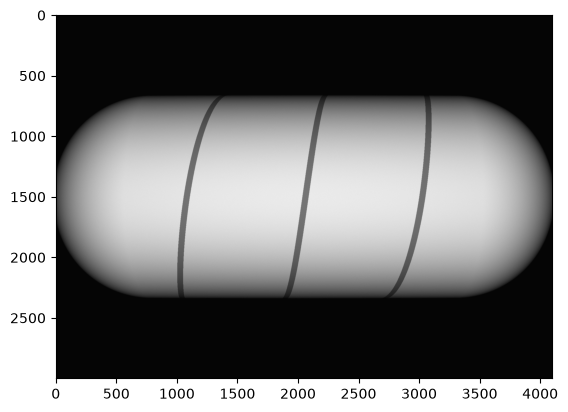

In [2]:
# import input_file

run = dataset.read_run(run_folder)
cam_img_data = dataset.read_frame(run, frame_name)
print(f"Input data shape: {cam_img_data.shape}")

#Preview the data
plt.imshow(cam_img_data, cmap='gray')


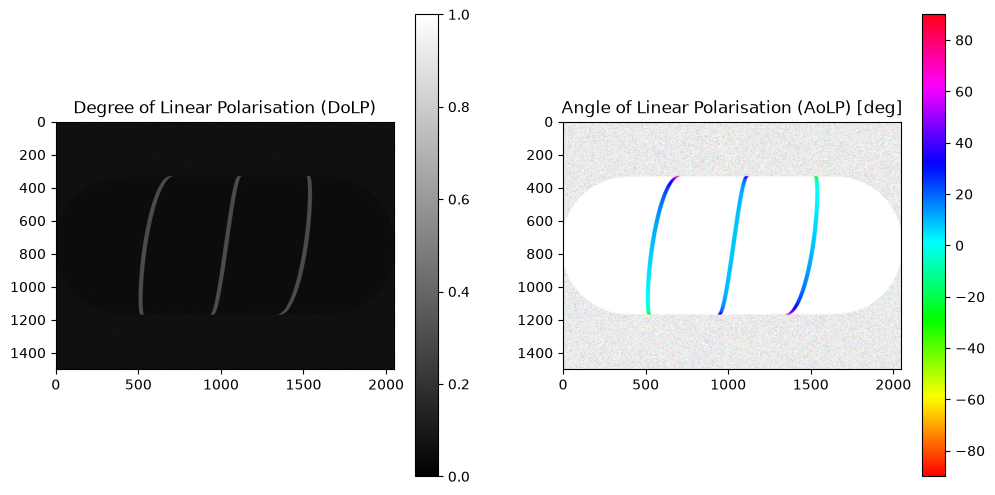

In [3]:
EPS = 1e-6

# Extract the four polarisation sub-images (half resolution) from the 2x2 super-pixels.
# Cast to float first: the raw data is unsigned integer, so I0 - I90 would otherwise wrap around.
sub_images = {
    polar_pattern[0]: cam_img_data[0::2, 0::2].astype(np.float32),  # top-left
    polar_pattern[1]: cam_img_data[0::2, 1::2].astype(np.float32),  # top-right
    polar_pattern[2]: cam_img_data[1::2, 0::2].astype(np.float32),  # bottom-left
    polar_pattern[3]: cam_img_data[1::2, 1::2].astype(np.float32),  # bottom-right
}
I0, I45, I90, I135 = sub_images[0], sub_images[45], sub_images[90], sub_images[135]

# Stokes parameters
S0 = 0.5 * ((I0 + I90) + (I45 + I135))  # total intensity, averaged over both polariser pairs
S1 = I0 - I90
S2 = I45 - I135

# Polarised / unpolarised intensity
I_pol = np.sqrt(S1**2 + S2**2)
I_unpol = np.clip(S0 - I_pol, 0.0, None)

# Degree of Linear Polarisation [0, 1] and Angle of Linear Polarisation [-pi/2, pi/2]
DoLP = np.clip(I_pol / (S0 + EPS), 0.0, 1.0)
AoLP = 0.5 * np.arctan2(S2, S1)
AoLP_deg = np.degrees(AoLP)  # [-90, 90] deg

# AoLP is only meaningful where the light is sufficiently polarised (suppress noise in low-DoLP areas)
AoLP_deg_masked = AoLP_deg.copy()
AoLP_deg_masked[DoLP < DoLP_threshold] = np.nan

# Preview the DoLP and AoLP images
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(DoLP, cmap='gray', vmin=0, vmax=1)
plt.title('Degree of Linear Polarisation (DoLP)')
plt.colorbar()
plt.subplot(1, 2, 2)
plt.imshow(AoLP_deg_masked, cmap='hsv', vmin=-90, vmax=90)
plt.title('Angle of Linear Polarisation (AoLP) [deg]')
plt.colorbar()
plt.show()

# Save the DoLP and AoLP images as .png files 


os.makedirs(save_location, exist_ok=True)

plt.imsave(f"{save_location}/DoLP.png", DoLP, cmap='gray', vmin=0, vmax=1)
plt.imsave(f"{save_location}/AoLP.png", AoLP_deg_masked, cmap='hsv', vmin=-90, vmax=90)


# 5 Mapping and flattening

The captured data is compensated for optical distortions due to the camera/lense system (based on the intrinsic calibration). The data is then projected on the surface of the mandrel's model and angel differences in due to the viewing incidence are compensated (AoLP to actual fibre angle), resulting in a data set where each pixel is assigned a measured fibre angle, a 3D position, and a 3D surface orientation. This 3D data set is then converted into a flattend gnomonic projection and illustrated. 

## Requirements
- Import of the AoLP, the camera intrinsics, and the camera position. 
- Compensation for optical distortions (adjustment of the pixel position only; the lens does not rotate the polarisation, so the AoLP is unchanged)
- Mapping of each pixel to the mandrels 3D model (3D position and surface orinetation)
- Adjustment of the AoLP based on the position and surface orientation
- Display and saving option of the gnomonic projection of this dataset.
- Saving of the processed dataset (fibre angle, position, surface angle) as npy
- The forward model below. Mapping inverts it, and the synthetic data generator uses it to render frames.
- Physical validation on the asymmetric demo mandrel (`Banana 1.STEP`) with known tow angles, because synthetic tests only prove that geometry and code are consistent, not the physics.

## Forward model
1. **Local frame** at surface point P with normal n: e_a is the mandrel axis projected into the tangent plane; e_r = e_a × n, the surface direction of mandrel rotation (n points out of the mandrel; the axis direction is oriented so that the mandrel turns counter-clockwise about it). Fibre direction **t = cos α · e_a + sin α · e_r**.
2. **Polarisation:** with the viewing ray v = (P − camera centre)/|…|, the reflected light is polarised perpendicular to fibre and ray: **E = v × t** (normalised).
3. **AoLP:** E in camera coordinates, ψ = atan2(E_y, E_x), wrapped to (−90°, 90°].
4. **Inverse:** E is rebuilt from ψ with E ⊥ v, then **t = E × n** (normalised) and α = atan2(t·e_r, t·e_a), wrapped to (−90°, 90°]. Closed form; ill-defined at grazing view, so pixels beyond an incidence limit are dropped.
5. **Rendering only (not inverted):** DoLP = 0.3 on tow, 0.05 on the bare mandrel, 0.02 in the background. S0 = L · ρ · cos(incidence) with the light at the camera, ρ = 0.4 on tow and 0.8 on the mandrel, and L set so the brightest pixel is about 3000 of 4095 counts.

The physical validation on the banana tests assumption 2 directly.

In [4]:
# Forward model (section 5). Drafted by Claude for review by the author.
# Production copy: digital_thread.forward_model (kept identical by the reference test).
# Conventions: world vectors (..., 3) in the STEP frame (mm); x_cam = R @ X + t with camera
# x right, y down, z forward; image angles from +x towards +y; the mandrel turns
# counter-clockwise about axis_dir (right-hand rule); normals point out of the mandrel.

import numpy as np

DOLP = {"tow": 0.3, "mandrel": 0.05, "background": 0.02}
ALBEDO = {"tow": 0.4, "mandrel": 0.8}


def wrap_angle(angle_deg):
    """Wrap an orientation angle to (-90, 90] degrees."""
    return 90.0 - np.mod(90.0 - np.asarray(angle_deg, dtype=float), 180.0)


def _unit(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)


def fibre_frame(normal, axis_dir):
    """Local surface frame (e_a, e_r): axis direction projected into the
    tangent plane, and the surface direction of mandrel rotation."""
    normal = np.asarray(normal, dtype=float)
    axis_dir = np.asarray(axis_dir, dtype=float)
    e_a = _unit(axis_dir - np.sum(axis_dir * normal, axis=-1, keepdims=True) * normal)
    e_r = np.cross(e_a, normal)
    return e_a, e_r


def fibre_direction(fibre_deg, normal, axis_dir):
    """Unit fibre direction t = cos(a) e_a + sin(a) e_r."""
    e_a, e_r = fibre_frame(normal, axis_dir)
    a = np.radians(np.asarray(fibre_deg, dtype=float))[..., None]
    return np.cos(a) * e_a + np.sin(a) * e_r


def _view_rays(point, rot, t):
    centre = -np.asarray(rot).T @ np.asarray(t, dtype=float)
    return _unit(np.asarray(point, dtype=float) - centre)


def cos_incidence(point, normal, rot, t):
    """Cosine of the angle between surface normal and the direction to the camera."""
    return np.sum(-_view_rays(point, rot, t) * np.asarray(normal), axis=-1)


def aolp_from_fibre(fibre_deg, point, normal, axis_dir, rot, t):
    """AoLP (deg) seen by the camera: light polarised along E = v x t."""
    v = _view_rays(point, rot, t)
    e = np.cross(v, fibre_direction(fibre_deg, normal, axis_dir))
    e_cam = e @ np.asarray(rot).T
    return wrap_angle(np.degrees(np.arctan2(e_cam[..., 1], e_cam[..., 0])))


def fibre_from_aolp(aolp_deg, point, normal, axis_dir, rot, t):
    """Inverse: rebuild E from the AoLP with E perpendicular to the ray, then
    the fibre is perpendicular to E and lies in the surface: t = E x n."""
    rot = np.asarray(rot)
    v_cam = _view_rays(point, rot, t) @ rot.T
    psi = np.radians(np.asarray(aolp_deg, dtype=float))
    ex, ey = np.cos(psi), np.sin(psi)
    ez = -(ex * v_cam[..., 0] + ey * v_cam[..., 1]) / v_cam[..., 2]
    e = np.stack([ex, ey, ez], axis=-1) @ rot
    fibre = np.cross(e, normal)
    e_a, e_r = fibre_frame(normal, axis_dir)
    along_r = np.sum(fibre * e_r, axis=-1)
    along_a = np.sum(fibre * e_a, axis=-1)
    return wrap_angle(np.degrees(np.arctan2(along_r, along_a)))


def s0(albedo, cos_incidence, light):
    """Total intensity, Lambertian with the light at the camera."""
    return light * albedo * np.clip(cos_incidence, 0.0, None)


def polariser_intensity(s0, dolp, aolp_deg, polariser_deg):
    """Intensity behind a linear polariser at polariser_deg (Malus)."""
    angle = np.radians(2.0 * (np.asarray(aolp_deg) - polariser_deg))
    return 0.5 * s0 * (1.0 + dolp * np.cos(angle))

# 6 Tow matching

All images that were captured throughout all revolutions of the FW process of the part will be analysed. For each revolution, the tow laid in that revolution is taken from the tow placement file and projected into the frame. Its planned position and angle are compared with the measured tow (the change between frames *k−1* and *k*), and the result is given as a table and as a visual overlay in the gnomonic projection.

## Requirements
- Import a tow placement file (Format: .csv with columns Point number, X, Y, Z in mm; see `demoData/planned_Path.csv`)
- The planned angle at each point is derived from the path tangent and the mandrel mesh, as the fibre angle against the mandrel axis
- For each revolution, based on the camera position and viewing angle, creation of a gnomonic projection of the last tow
- For each revolution, one table row per visible crossing of its tow, with the planned position and angle and the Δ position and Δ angle of the measured tow. A revolution whose tow is not visible gets a "not visible" row
- Preview and saving of the overlay image (planned tow edges on the processed image)

In [5]:
# Touch-down model (shared conventions, used by section 6). Drafted by Claude for review.
# Production copy: digital_thread.touch_down (kept identical by the reference test).

import numpy as np


def body_angle(points, axis_point, axis_dir):
    """Unwrapped angle (deg) of each path point about the axis, counter-clockwise
    about axis_dir (right-hand rule), in path order. Zero is the STEP X
    direction projected normal to the axis (Y if the axis is along X)."""
    a = np.asarray(axis_dir, dtype=float)
    a = a / np.linalg.norm(a)
    zero = np.array([1.0, 0.0, 0.0]) if abs(a[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    e1 = zero - (zero @ a) * a
    e1 /= np.linalg.norm(e1)
    e2 = np.cross(a, e1)
    rel = np.asarray(points, dtype=float) - axis_point
    return np.degrees(np.unwrap(np.arctan2(rel @ e2, rel @ e1)))


def mandrel_angle(points, axis_point, axis_dir, touch_down_deg, pin_phase_deg):
    """Mandrel angle (deg, counted from the last pin pulse before winding) at
    which each point is laid. A point at body angle phi touches down when
    mandrel angle + phi = touch-down angle, so later tow lies at smaller phi.
    The first point is laid within the first revolution."""
    phi = body_angle(points, axis_point, axis_dir)
    first = np.mod(touch_down_deg - phi[0] - pin_phase_deg, 360.0)
    return first + (phi[0] - phi)


def revolution_index(points, axis_point, axis_dir, touch_down_deg, pin_phase_deg):
    """Revolution k in which each point is laid (k = 0 for the first point)."""
    theta = mandrel_angle(points, axis_point, axis_dir, touch_down_deg, pin_phase_deg)
    return np.floor(theta / 360.0).astype(int)

# 7 Data export

The data is exported to the needs of the digital thread. The first version writes, per run, the tow table (slice 6) as CSV, plus the mapped arrays. The 3DEXPERIENCE adapter is future work; its requirements are defined later.

# 8 Implementation decisions

Rules for this section:
- It lists only implementation decisions that are not critical to the scientific value of the software. Decisions that matter for understanding the system go into the main sections.
- Each decision is deleted from this list once it is implemented.

Open decisions:
- **Delivery:** a uv-managed environment on the workstation, started from a desktop shortcut. The touch GUI framework is chosen in the slice 1 grill.